# Figure 2d. TransMap-local versus other program-level scores

S-LDSC marginal τ* of variant annotations built from four program-level association scores (TransMap-local, TransPCO*, Eigengene, AUCell), using programs defined by Hotspot or by WGCNA. Each annotation is conditional on the baseline-LD model; meta-analysis across 57 traits and the brain- and blood-related subsets. Error bars are τ* ± 1.9 × SE, as in the original figure code; red asterisks mark P < 0.05 with τ* > 0.

Input: `data/Figure_2d_sldsc_program_scores.rds`.

In [1]:
library(ggplot2)
res <- readRDS("data/Figure_2d_sldsc_program_scores.rds")
res

program_source,method,trait,tau,tau_se,pvalue
<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>
WGCNA,Eigengene,All traits (57),-0.056831314,0.01585104,3.366443e-04
WGCNA,TransPCO*,All traits (57),0.011153142,0.02005015,5.780316e-01
WGCNA,TransMap-local,All traits (57),0.126331150,0.02167245,5.572311e-09
WGCNA,AUCell,All traits (57),-0.029545517,0.02420045,2.221367e-01
Hotspot,Eigengene,All traits (57),0.012627883,0.01865692,4.985030e-01
Hotspot,TransPCO*,All traits (57),0.112993855,0.01724688,5.694134e-11
Hotspot,TransMap-local,All traits (57),0.217628104,0.01690810,6.534991e-38
Hotspot,AUCell,All traits (57),-0.005377735,0.02037731,7.918508e-01
WGCNA,Eigengene,Blood-related traits (22),-0.088754996,0.02925927,2.418171e-03


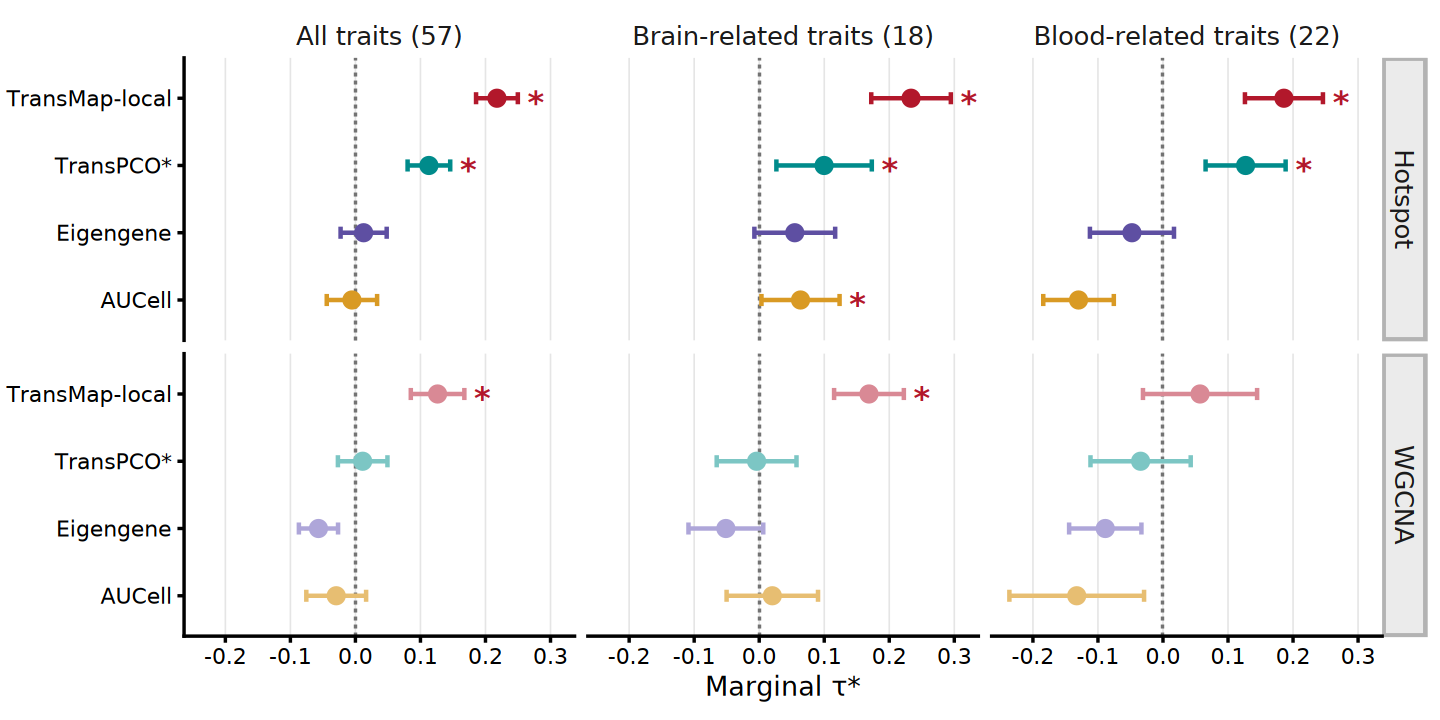

In [2]:
colors <- c("Hotspot TransMap-local" = "#B2182B", "Hotspot TransPCO*" = "#008B8B",
            "Hotspot Eigengene" = "#5E4FA2", "Hotspot AUCell" = "#D99A24",
            "WGCNA TransMap-local" = "#D98995", "WGCNA TransPCO*" = "#7CC6C4",
            "WGCNA Eigengene" = "#AEA6D9", "WGCNA AUCell" = "#E7BE72")
res$colour_group <- paste(res$program_source, res$method)
res$method <- factor(res$method, levels = rev(levels(res$method)))
res$ci_low  <- res$tau - 1.9 * res$tau_se
res$ci_high <- res$tau + 1.9 * res$tau_se
res$star    <- ifelse(res$pvalue < 0.05 & res$tau > 0, "*", "")

p <- ggplot(res, aes(y = method, colour = colour_group)) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey45") +
  geom_errorbar(aes(xmin = ci_low, xmax = ci_high), width = 0.18, orientation = "y", linewidth = 0.95) +
  geom_point(aes(x = tau), size = 4) +
  geom_text(aes(x = ci_high + 0.015, label = star), colour = "#B2182B",
            size = 6.6, fontface = "bold", hjust = 0, vjust = 0.65) +
  facet_grid(program_source ~ trait) +
  scale_colour_manual(values = colors, guide = "none") +
  labs(x = expression(paste("Marginal ", tau, "*")), y = NULL) +
  theme_classic(base_size = 16) +
  theme(strip.background.x = element_blank(), strip.text = element_text(size = 15),
        strip.background.y = element_rect(fill = "grey92", colour = "grey70"),
        panel.grid.major.x = element_line(colour = "grey90", linewidth = 0.35))

options(repr.plot.width = 12, repr.plot.height = 6)
p